# Train YOLO11N: Brain Tumor Detection (Glioma / Meningioma / No Tumor / Pituitary)

Local CUDA training of `yolo11n.pt` for 100 epochs with early stopping disabled. Uses `dataset_yolo_mri/` in this repo (no download), writes to a unique `yolo11n_outputs/runs_100ep_20261113/` directory, and saves validation metrics and figures. The best checkpoint is copied to `models/yolo11n_best_100ep.pt`. Run inside the repo folder with a CUDA-enabled venv kernel; run all cells top to bottom.

## 1. GPU check + config

In [4]:
import os, re, gc, json, shutil
from pathlib import Path
import torch

if not torch.cuda.is_available():
    raise RuntimeError('CUDA is unavailable. Select the kernel of a venv that has a CUDA build of PyTorch (see README / setup notes).')
print('GPU:', torch.cuda.get_device_name(0), '| torch', torch.__version__, '| CUDA', torch.version.cuda)

import ultralytics, yaml
from ultralytics import YOLO
print('ultralytics', ultralytics.__version__)

NAME = 'yolo11n'
MODEL_SCALE = 'yolo11n.pt'
if NAME.startswith('yolo26') and tuple(int(x) for x in re.findall(r'\d+', ultralytics.__version__)[:3]) < (8, 4, 0):
    raise RuntimeError('YOLO26 needs ultralytics>=8.4. In a terminal with the venv active run: pip install -U ultralytics  (then restart the kernel).')

# ---------------- config: keep IDENTICAL in all 9 notebooks so the comparison is fair ----------------
IMGSZ, EPOCHS, SEED = 640, 100, 42
PATIENCE = EPOCHS + 1                  # early stopping cannot trigger before epoch 100
BATCH = 16
WORKERS = 2 if os.name == 'nt' else 8  # data-loader workers (set 0 if the Windows kernel ever hangs)
CLASS_NAMES = ['Glioma', 'Meningioma', 'No Tumor', 'Pituitary']   # class ids 0..3 (same as the dataset's own labels)

def find_repo_root():
    for p in [Path.cwd(), *Path.cwd().parents]:
        if (p / 'dataset_yolo_mri').is_dir():
            return p
    raise RuntimeError("Could not find 'dataset_yolo_mri'. Open the repo folder in VS Code so the notebook runs inside it.")

REPO_ROOT = find_repo_root()
OUT_DIR = REPO_ROOT / f'{NAME}_outputs'      # results JSON, runs/, val/, figures/ for this model
MODELS_DIR = REPO_ROOT / 'models'            # best weights copied here (used by app.py)
print('Repo:', REPO_ROOT, '| outputs:', OUT_DIR)

GPU: NVIDIA GeForce RTX 4060 Laptop GPU | torch 2.12.1+cu126 | CUDA 12.6
ultralytics 8.4.211
Repo: e:\brain-tumor-yolo-paper-rerun\brain-tumor-yolo | outputs: e:\brain-tumor-yolo-paper-rerun\brain-tumor-yolo\yolo11n_outputs


## 2. Dataset (flattened local copy, built once)

In [5]:
SRC_DIR = REPO_ROOT / 'dataset_yolo_mri'
DATA_DIR = REPO_ROOT / '_yolo_data'      # flattened YOLO copy of SRC_DIR (git-ignored, built once, then reused)
FORCE_REBUILD = False                    # True = delete and rebuild the flattened dataset
IMG_EXT = {'.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff', '.webp'}
SAFE = [c.replace(' ', '') for c in CLASS_NAMES]
canon = {re.sub(r'[^a-z]', '', c.lower()): c for c in CLASS_NAMES}

def build_dataset():
    from collections import Counter
    id_votes = {c: Counter() for c in CLASS_NAMES}
    n_img, n_missing = Counter(), 0
    for split_dir in sorted(p for p in SRC_DIR.iterdir() if p.is_dir()):
        split = {'train': 'train', 'val': 'val', 'valid': 'val', 'validation': 'val'}.get(split_dir.name.lower())
        if split is None: continue
        for class_dir in sorted(p for p in split_dir.iterdir() if p.is_dir()):
            cname = canon.get(re.sub(r'[^a-z]', '', class_dir.name.lower()))
            if cname is None:
                raise RuntimeError(f'Unknown class folder {class_dir} (expected one of {CLASS_NAMES})')
            img_dir = class_dir / 'images' if (class_dir / 'images').is_dir() else class_dir
            lbl_dir = class_dir / 'labels' if (class_dir / 'labels').is_dir() else class_dir
            img_out, lbl_out = DATA_DIR / split / 'images', DATA_DIR / split / 'labels'
            img_out.mkdir(parents=True, exist_ok=True); lbl_out.mkdir(parents=True, exist_ok=True)
            for img in sorted(img_dir.iterdir()):
                if img.suffix.lower() not in IMG_EXT: continue
                lbl = lbl_dir / (img.stem + '.txt')
                if not lbl.exists(): n_missing += 1; continue
                dest, k = f'{cname.replace(" ", "")}_{img.name}', 0
                while (img_out / dest).exists():
                    k += 1; dest = f'{cname.replace(" ", "")}_{k}_{img.name}'
                shutil.copy2(img, img_out / dest); shutil.copy2(lbl, lbl_out / (Path(dest).stem + '.txt'))
                n_img[(split, cname)] += 1
                for line in lbl.read_text().splitlines():
                    if line.split(): id_votes[cname][int(float(line.split()[0]))] += 1
    return id_votes, n_img, n_missing

if FORCE_REBUILD and DATA_DIR.exists():
    shutil.rmtree(DATA_DIR)

if not (DATA_DIR / 'data.yaml').exists():
    if DATA_DIR.exists(): shutil.rmtree(DATA_DIR)
    id_votes, n_img, n_missing = build_dataset()
    dominant = {c: id_votes[c].most_common(1)[0][0] for c in CLASS_NAMES if id_votes[c]}
    print('dominant label id per class folder:', dominant)
    for c in CLASS_NAMES:
        tot = sum(id_votes[c].values()); other = tot - id_votes[c][dominant.get(c, -1)]
        print(f'  {c:11s} boxes={tot:5d}  with a different class id: {other}')
    expected = {c: i for i, c in enumerate(CLASS_NAMES)}
    if dominant != expected:
        shutil.rmtree(DATA_DIR, ignore_errors=True)
        raise RuntimeError(f"Label ids in the dataset do not match CLASS_NAMES order.\nfound   : {dominant}\nexpected: {expected}\n"
                           "Fix CLASS_NAMES in this config cell (same order in all notebooks).")
    if n_missing: print('WARNING: images without a label file were skipped:', n_missing)
    with open(DATA_DIR / 'data.yaml', 'w') as f:
        yaml.safe_dump({'path': DATA_DIR.as_posix(), 'train': 'train/images', 'val': 'val/images',
                        'names': {i: n for i, n in enumerate(CLASS_NAMES)}}, f, sort_keys=False)
else:
    print(f'Reusing prepared dataset at {DATA_DIR}')

_names = yaml.safe_load((DATA_DIR / 'data.yaml').read_text())['names']
_names = [_names[i] for i in sorted(_names)] if isinstance(_names, dict) else list(_names)
assert _names == CLASS_NAMES, f'{DATA_DIR}/data.yaml has classes {_names}; set FORCE_REBUILD = True and re-run this cell.'
for s in ('train', 'val'):
    print(s, 'images:', len(list((DATA_DIR / s / 'images').glob('*'))))
print('classes:', _names)

Reusing prepared dataset at e:\brain-tumor-yolo-paper-rerun\brain-tumor-yolo\_yolo_data
train images: 4737
val images: 510
classes: ['Glioma', 'Meningioma', 'No Tumor', 'Pituitary']


## 3. Train (no early stopping)

In [6]:
DATA_YAML = str(DATA_DIR / 'data.yaml')
RUN_NAME = 'runs_100ep_20261113'
RUN_DIR = OUT_DIR / RUN_NAME
VAL_NAME = f'{RUN_NAME}_val'
VAL_DIR = OUT_DIR / VAL_NAME
LAST, BEST = RUN_DIR / 'weights' / 'last.pt', RUN_DIR / 'weights' / 'best.pt'
if RUN_DIR.exists() or VAL_DIR.exists():
    raise FileExistsError(f'Refusing to reuse prior outputs: {RUN_DIR} or {VAL_DIR}')
OUT_DIR.mkdir(parents=True, exist_ok=True)

def cleanup():
    gc.collect(); torch.cuda.empty_cache()

m = YOLO(MODEL_SCALE)
m.train(data=DATA_YAML, imgsz=IMGSZ, epochs=EPOCHS, batch=BATCH, workers=WORKERS, device=0,
        seed=SEED, amp=True, patience=PATIENCE, project=str(OUT_DIR), name=RUN_NAME,
        exist_ok=False, plots=True)
RUN_DIR = Path(m.trainer.save_dir)
LAST, BEST = RUN_DIR / 'weights' / 'last.pt', RUN_DIR / 'weights' / 'best.pt'
assert LAST.exists(), f'last.pt not found at {LAST}'
assert BEST.exists(), f'best.pt not found at {BEST}'
import pandas as pd
epoch_log = pd.read_csv(RUN_DIR / 'results.csv')
assert len(epoch_log) == EPOCHS, f'Expected exactly {EPOCHS} completed epochs; found {len(epoch_log)}'
assert int(epoch_log['epoch'].iloc[-1]) == EPOCHS, f'Expected final epoch number {EPOCHS}; found {epoch_log["epoch"].iloc[-1]}'

best_model = YOLO(str(BEST))
got = [best_model.names[i] for i in sorted(best_model.names)]
assert got == CLASS_NAMES, f'Unexpected class names in trained weights: {got}'
print('Model classes:', got)

Ultralytics 8.4.211  Python-3.14.4 torch-2.12.1+cu126 CUDA:0 (NVIDIA GeForce RTX 4060 Laptop GPU, 8188MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=e:\brain-tumor-yolo-paper-rerun\brain-tumor-yolo\_yolo_data\data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0,

## 4. Training curves

epochs completed: 100/100 | best epoch (mAP50-95): 98


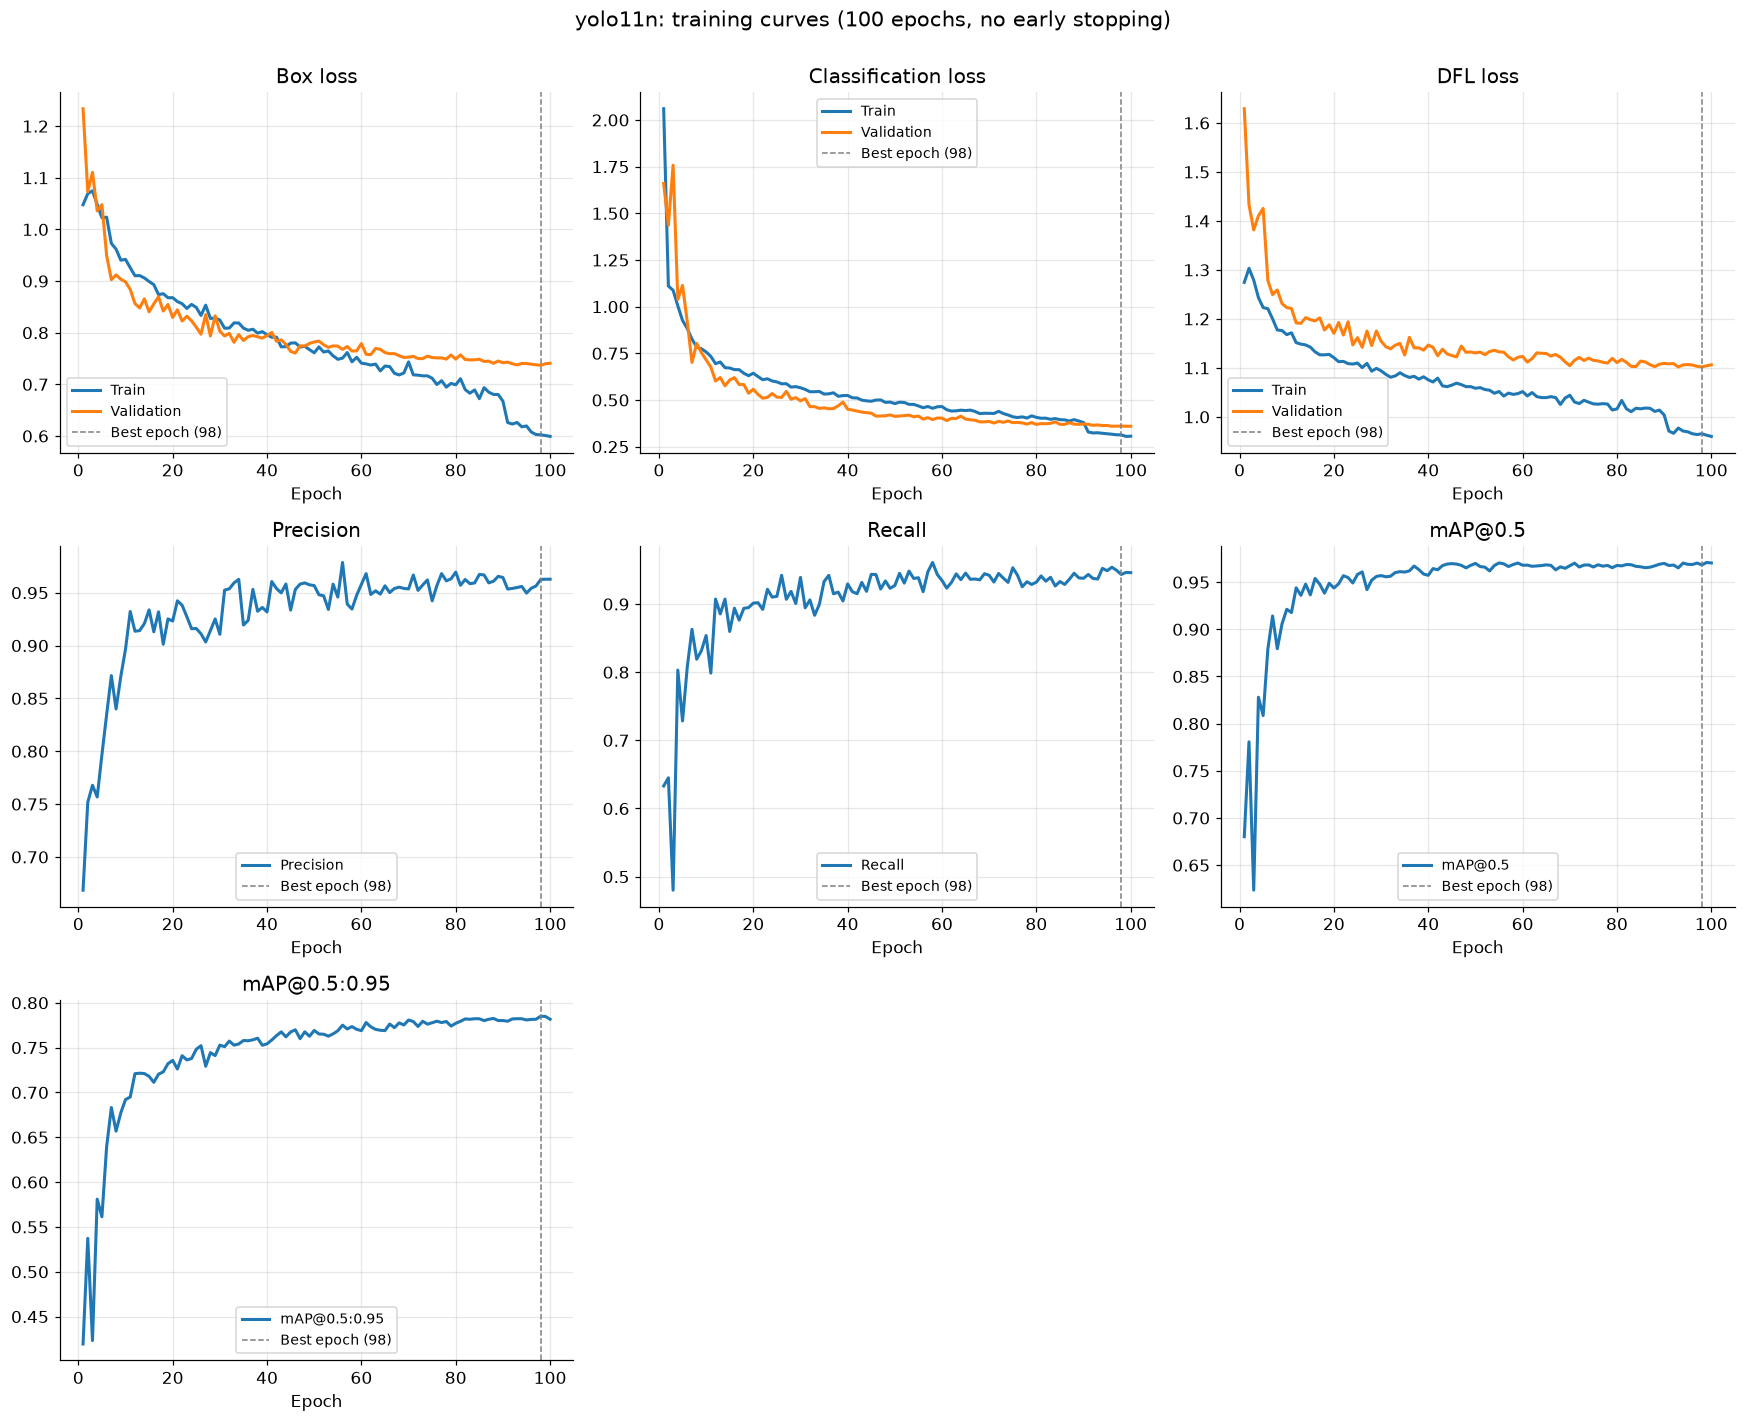

In [7]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 300, 'font.size': 11, 'axes.grid': True, 'grid.alpha': 0.3,
                     'axes.spines.top': False, 'axes.spines.right': False})

FIG_DIR = RUN_DIR / 'paper_figures'; FIG_DIR.mkdir(exist_ok=False)
df = pd.read_csv(RUN_DIR / 'results.csv'); df.columns = [c.strip() for c in df.columns]
n_epochs = len(df)
best_idx = int(df['metrics/mAP50-95(B)'].idxmax()); best_epoch = int(df['epoch'].iloc[best_idx])
print(f'epochs completed: {n_epochs}/{EPOCHS} | best epoch (mAP50-95): {best_epoch}')
assert n_epochs == EPOCHS, f'Expected exactly {EPOCHS} completed epochs; found {n_epochs}'

panels = [
    ('Box loss', [('train/box_loss', 'Train'), ('val/box_loss', 'Validation')]),
    ('Classification loss', [('train/cls_loss', 'Train'), ('val/cls_loss', 'Validation')]),
    ('DFL loss', [('train/dfl_loss', 'Train'), ('val/dfl_loss', 'Validation')]),
    ('Precision', [('metrics/precision(B)', 'Precision')]),
    ('Recall', [('metrics/recall(B)', 'Recall')]),
    ('mAP@0.5', [('metrics/mAP50(B)', 'mAP@0.5')]),
    ('mAP@0.5:0.95', [('metrics/mAP50-95(B)', 'mAP@0.5:0.95')]),
]
panels = [p for p in panels if all(c in df.columns for c, _ in p[1]) and any(df[c].abs().sum() > 0 for c, _ in p[1])]
ncols = 3; nrows = int(np.ceil(len(panels) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(16, 4.3 * nrows), squeeze=False)
axes = axes.ravel()
for ax in axes: ax.set_visible(False)
for ax, (title, cols) in zip(axes, panels):
    ax.set_visible(True)
    for c, lab in cols:
        ax.plot(df['epoch'], df[c], lw=2, label=lab)
    ax.axvline(best_epoch, color='gray', ls='--', lw=1, label=f'Best epoch ({best_epoch})')
    ax.set_title(title); ax.set_xlabel('Epoch'); ax.legend(fontsize=9)
fig.suptitle(f'{NAME}: training curves ({n_epochs} epochs, no early stopping)', fontsize=14, y=1.0)
fig.tight_layout()
fig.savefig(FIG_DIR / 'training_curves.png', bbox_inches='tight'); fig.savefig(FIG_DIR / 'training_curves.pdf', bbox_inches='tight')
plt.show(); plt.close(fig)

## 5. Validate best.pt

In [8]:
metrics = best_model.val(data=DATA_YAML, imgsz=IMGSZ, batch=8, workers=WORKERS, device=0,
                         project=str(OUT_DIR), name=VAL_NAME, exist_ok=False, plots=True)

map50, map50_95 = float(metrics.box.map50), float(metrics.box.map)
precision, recall = float(metrics.box.mp), float(metrics.box.mr)
per_class_ap50 = {best_model.names[int(i)]: float(ap) for i, ap in zip(metrics.box.ap_class_index, metrics.box.ap50)}
per_class_ap = {best_model.names[int(i)]: float(ap) for i, ap in zip(metrics.box.ap_class_index, metrics.box.maps[metrics.box.ap_class_index]) } if hasattr(metrics.box, 'maps') else {}
print(f'mAP50: {map50:.4f}  mAP50-95: {map50_95:.4f}  precision: {precision:.4f}  recall: {recall:.4f}')
print('per-class AP50:', {k: round(v, 4) for k, v in per_class_ap50.items()})

Ultralytics 8.4.211  Python-3.14.4 torch-2.12.1+cu126 CUDA:0 (NVIDIA GeForce RTX 4060 Laptop GPU, 8188MiB)
YOLO11n summary (fused): 101 layers, 2,597,780 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access  (ping: 0.0±0.0 ms, read: 110.1±45.9 MB/s, size: 25.1 KB)
val: Scanning E:\brain-tumor-yolo-paper-rerun\brain-tumor-yolo\_yolo_data\val\labels.cache... 510 images, 1 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 510/510 152.8Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 64/64 9.4it/s 6.8s<0.1s
                   all        510        554      0.963      0.944      0.968      0.782
                Glioma        135        153      0.932      0.895      0.933      0.747
            Meningioma        140        142      0.993          1      0.994       0.82
              No Tumor         98         98          1      0.992      0.995      0.815
             Pituitary        154        161      0.928      0.888 

## 6. Confusion matrix, PR and F1 curves

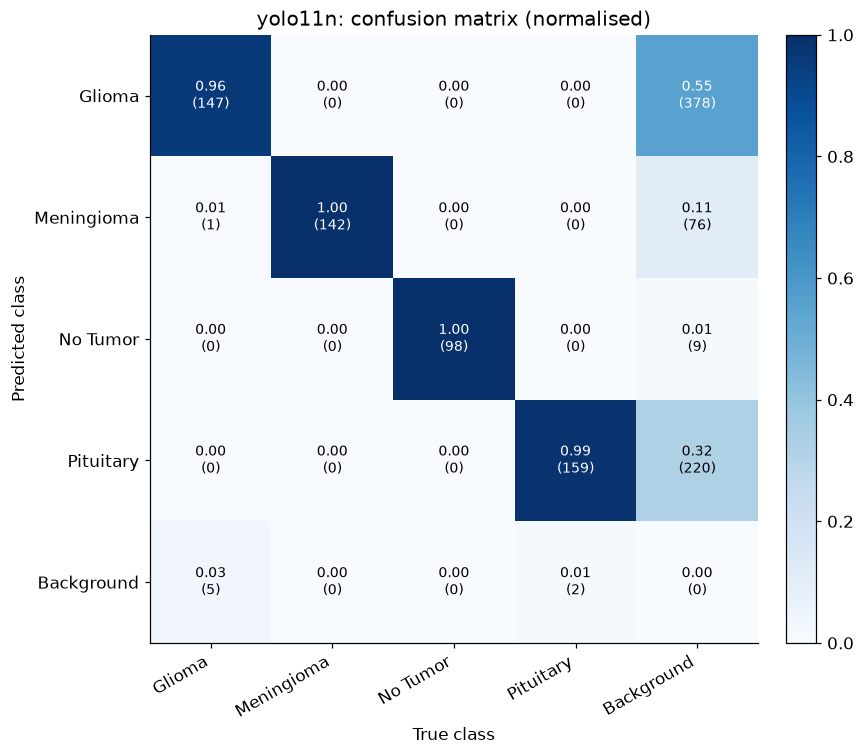

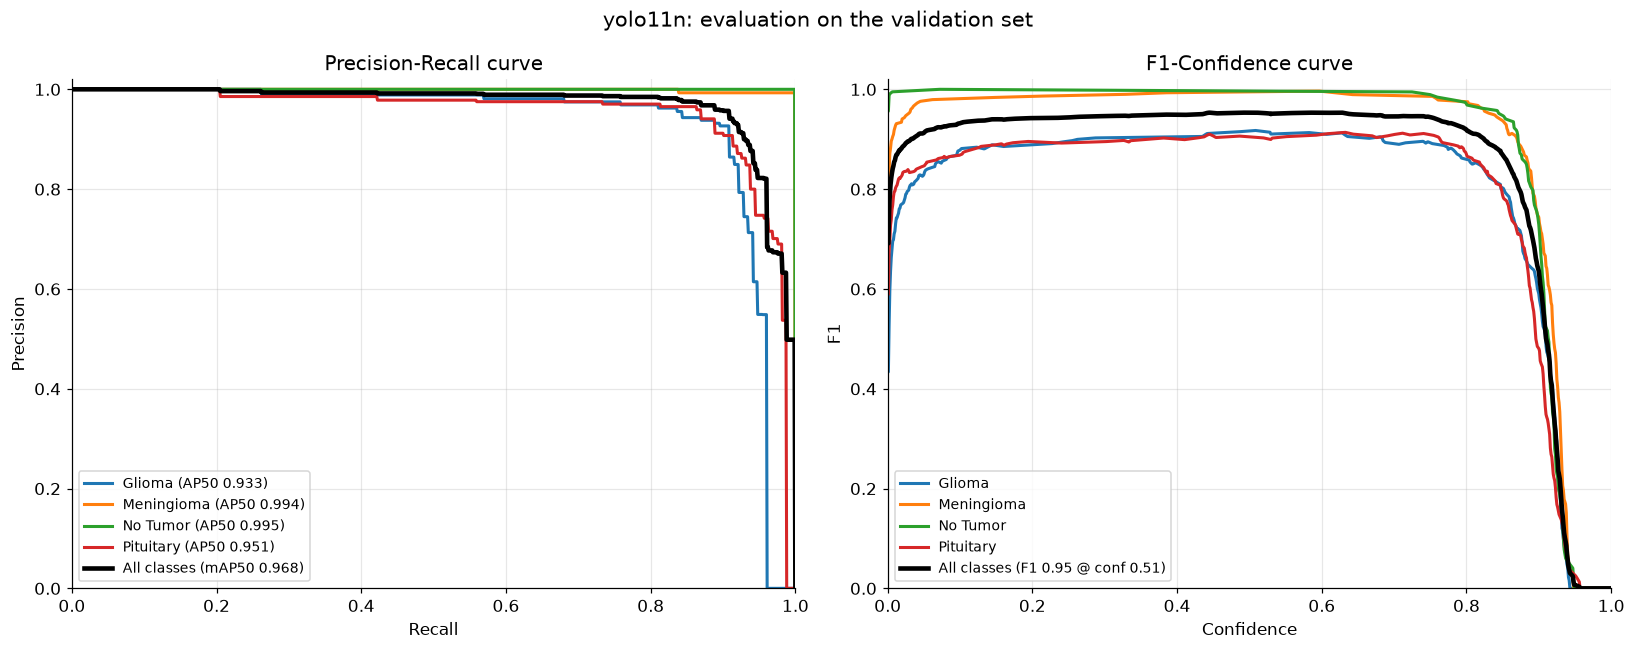

In [9]:
# ---- confusion matrix (row = predicted, column = true; columns normalised) ----
cm = np.array(metrics.confusion_matrix.matrix, dtype=float)
labels = CLASS_NAMES + ['Background']
cm_n = cm / np.maximum(cm.sum(axis=0, keepdims=True), 1e-9)
fig, ax = plt.subplots(figsize=(8, 7))
ax.grid(False)
im = ax.imshow(cm_n, cmap='Blues', vmin=0, vmax=1)
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(j, i, f'{cm_n[i, j]:.2f}\n({int(cm[i, j])})', ha='center', va='center', fontsize=9,
                color='white' if cm_n[i, j] > 0.5 else 'black')
ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels, rotation=30, ha='right')
ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels)
ax.set_xlabel('True class'); ax.set_ylabel('Predicted class'); ax.set_title(f'{NAME}: confusion matrix (normalised)')
fig.colorbar(im, fraction=0.046, pad=0.04); fig.tight_layout()
fig.savefig(FIG_DIR / 'confusion_matrix.png', bbox_inches='tight'); fig.savefig(FIG_DIR / 'confusion_matrix.pdf', bbox_inches='tight')
plt.show(); plt.close(fig)

# ---- precision-recall and F1-confidence curves ----
try:
    curves = metrics.box.curves_results
    px, py = np.asarray(curves[0][0]), np.asarray(curves[0][1])
    fx, fy = np.asarray(curves[1][0]), np.asarray(curves[1][1])
    idx = [int(i) for i in metrics.box.ap_class_index]
    fig, axs = plt.subplots(1, 2, figsize=(15, 6))
    for k, ci in enumerate(idx):
        axs[0].plot(px, py[k], lw=2, label=f'{best_model.names[ci]} (AP50 {metrics.box.ap50[k]:.3f})')
        axs[1].plot(fx, fy[k], lw=2, label=best_model.names[ci])
    axs[0].plot(px, py.mean(0), 'k', lw=3, label=f'All classes (mAP50 {map50:.3f})')
    bi = int(fy.mean(0).argmax())
    axs[1].plot(fx, fy.mean(0), 'k', lw=3, label=f'All classes (F1 {fy.mean(0)[bi]:.2f} @ conf {fx[bi]:.2f})')
    axs[0].set(xlabel='Recall', ylabel='Precision', xlim=(0, 1), ylim=(0, 1.02), title='Precision-Recall curve')
    axs[1].set(xlabel='Confidence', ylabel='F1', xlim=(0, 1), ylim=(0, 1.02), title='F1-Confidence curve')
    for a in axs: a.legend(loc='lower left', fontsize=9)
    fig.suptitle(f'{NAME}: evaluation on the validation set', fontsize=14); fig.tight_layout()
    fig.savefig(FIG_DIR / 'pr_f1_curves.png', bbox_inches='tight'); fig.savefig(FIG_DIR / 'pr_f1_curves.pdf', bbox_inches='tight')
    plt.show(); plt.close(fig)
except Exception as e:
    print('Custom PR/F1 plot skipped (', type(e).__name__, e, '); showing Ultralytics plots instead.')
    from PIL import Image
    for f in ('BoxPR_curve.png', 'BoxF1_curve.png'):
        p = Path(metrics.save_dir) / f
        if p.exists():
            plt.figure(figsize=(9, 7)); plt.imshow(Image.open(p)); plt.axis('off'); plt.show()

## 7. Save weights + results JSON

In [10]:
try:
    info = best_model.info(verbose=False, imgsz=IMGSZ)
except TypeError:
    info = best_model.info(verbose=False)
except Exception:
    info = None
params_m = round(info[1] / 1e6, 3) if info else None
gflops = round(float(info[3]), 2) if info else None
speed = {k: round(float(v), 3) for k, v in getattr(metrics, 'speed', {}).items()}

args = yaml.safe_load((RUN_DIR / 'args.yaml').read_text())
used = {k: args.get(k) for k in ('imgsz', 'epochs', 'batch', 'patience', 'seed', 'optimizer', 'workers', 'amp')}

MODELS_DIR.mkdir(exist_ok=True)
best_dst = MODELS_DIR / f'{NAME}_best_100ep.pt'
shutil.copy2(BEST, best_dst)

results_payload = {
    'model_family': NAME, 'model_scale': MODEL_SCALE, 'classes': CLASS_NAMES,
    'config': used,
    'training': {'epochs_completed': n_epochs, 'best_epoch': best_epoch, 'early_stopping': False},
    'model_info': {'params_m': params_m, 'gflops': gflops},
    'speed_ms_per_image': speed,
    'metrics': {'map50': map50, 'map50_95': map50_95, 'precision': precision, 'recall': recall,
                'per_class_ap50': per_class_ap50},
    'eval_split': 'val',
    'notes': None,
}
results_path = OUT_DIR / f'results_{NAME}_100ep.json'
with open(results_path, 'w') as f:
    json.dump(results_payload, f, indent=2)
print('saved weights:', best_dst)
print('saved results:', results_path)
print('config used:', used)

saved weights: e:\brain-tumor-yolo-paper-rerun\brain-tumor-yolo\models\yolo11n_best_100ep.pt
saved results: e:\brain-tumor-yolo-paper-rerun\brain-tumor-yolo\yolo11n_outputs\results_yolo11n_100ep.json
config used: {'imgsz': 640, 'epochs': 100, 'batch': 16, 'patience': 101, 'seed': 42, 'optimizer': 'auto', 'workers': 2, 'amp': True}


## 8. Sample predictions

In [ ]:
import cv2

val_imgs = sorted((DATA_DIR / 'val' / 'images').glob('*'))
picked = []
for s in SAFE:
    picked += [p for p in val_imgs if p.name.startswith(s + '_')][:2]

fig, axes = plt.subplots(2, 4, figsize=(20, 10))
axes = axes.ravel()
for ax in axes: ax.axis('off')
for ax, p in zip(axes, picked[:8]):
    r = best_model.predict(str(p), imgsz=IMGSZ, conf=0.25, device=0, verbose=False)[0]
    preds = sorted({best_model.names[int(c)] for c in r.boxes.cls}) or ['none']
    ax.imshow(cv2.cvtColor(r.plot(), cv2.COLOR_BGR2RGB))
    ax.set_title(f'GT: {p.name.split("_")[0]} | Pred: {", ".join(preds)}', fontsize=10)
fig.tight_layout()
fig.savefig(FIG_DIR / 'sample_predictions.png', bbox_inches='tight')
plt.show(); plt.close(fig)

## 9. Free GPU memory

In [12]:
del best_model, metrics
cleanup()
print('Done:', NAME, '| figures for the paper:', FIG_DIR)

Done: yolo11n | figures for the paper: E:\brain-tumor-yolo-paper-rerun\brain-tumor-yolo\yolo11n_outputs\runs_100ep_20261113\paper_figures
